# Exercise 20 – A catalogue of cluster descriptors

**Week 4 · Descriptors and unsupervised learning**

| descriptor | definition |
|---|---|
| pair distances | histogram of all $r_{ij}$ |
| coordination numbers | histogram of the number of neighbours ($r_{ij} < 1.2$) per atom |
| connectivity graph spectrum | sorted eigenvalues of $-A$, with $A_{ij} = 1$ for neighbours |
| Coulomb matrix spectrum | sorted eigenvalues of the matrix $1/r_{ij}$ (1 on the diagonal) |

All four are invariant to rotations, translations and permutations of the atoms.

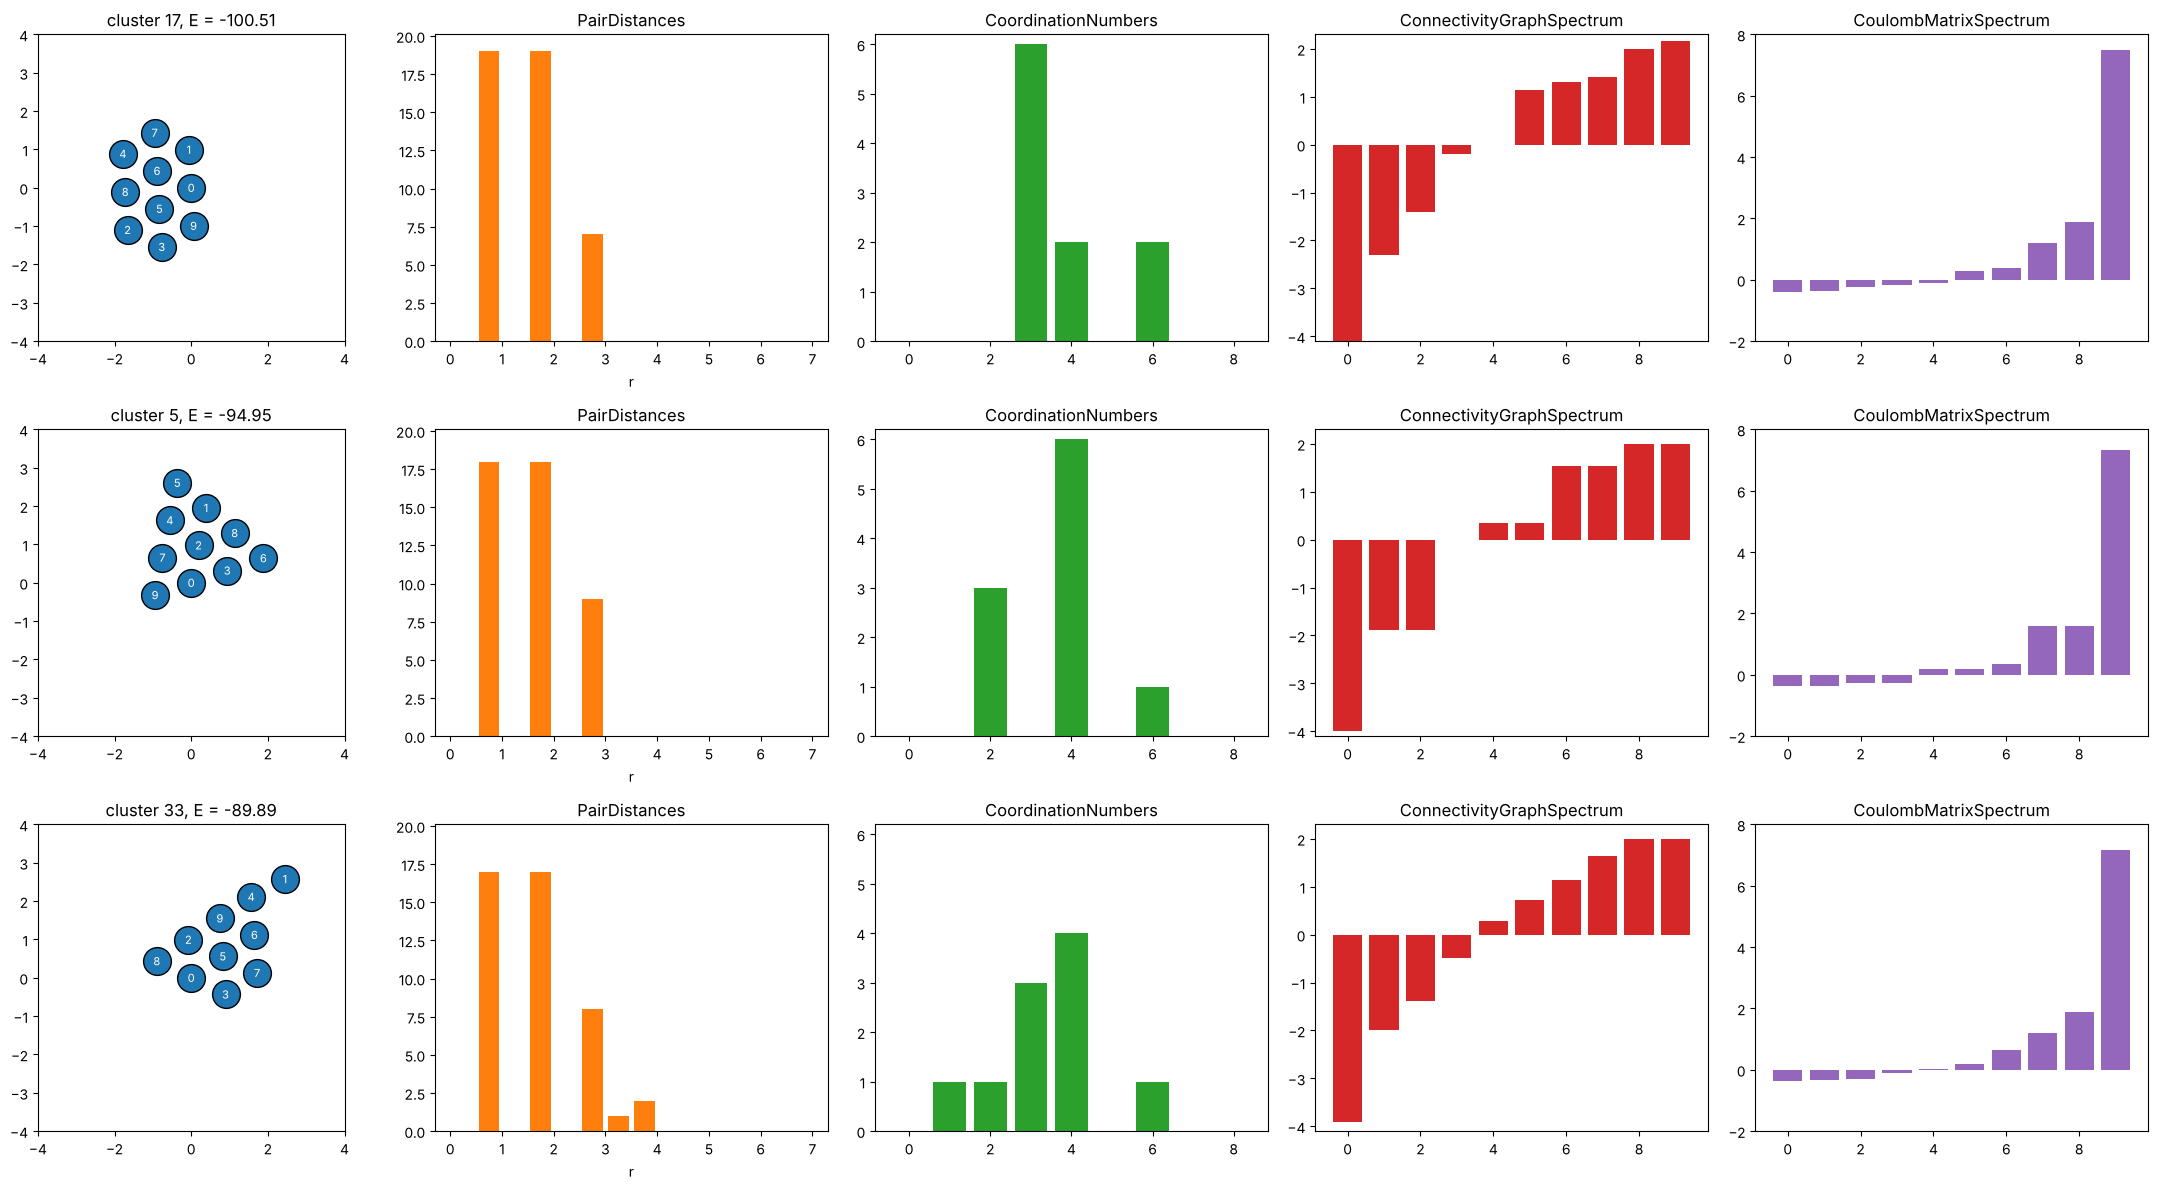

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from comphy import DATA_DIR
from comphy.atoms import LennardJones
from comphy.clusters import plot_cluster
from comphy.descriptors import (ConnectivityGraphSpectrum, CoordinationNumbers,
                                CoulombMatrixSpectrum, PairDistances)

raw = np.loadtxt(DATA_DIR / "lj10clusters.txt")
positions = raw.reshape(len(raw), -1, 2)
calc = LennardJones()
descriptors = [PairDistances(), CoordinationNumbers(), ConnectivityGraphSpectrum(),
               CoulombMatrixSpectrum()]

fig, axes = plt.subplots(3, 5, figsize=(22, 12))
for row, idx in zip(axes, [17, 5, 33]):
    plot_cluster(row[0], positions[idx], size=400)
    row[0].set(xlim=(-4, 4), ylim=(-4, 4), title=f"cluster {idx}, E = {calc.energy(positions[idx]):.2f}")
    for ax, d in zip(row[1:], descriptors):
        d.draw(ax, positions[idx])
fig.tight_layout()
plt.show()